# Tarea 2: Python para análisis de datos

## Objetivos de la tarea:
### * Crear gráficos
### * Definir funciones sencillas
#### Se utilizará la misma base de datos que en la Tarea 1, que corresponde a estimaciones satelitales de biomasa húmeda de sargazo flotante en toneladas. 

## Características de la base de datos
**Fuente:** Comisión Nacional para el Conocimiento y Uso de la Biodiversidad (CONABIO).

**Plataforma:** Sistema de Información y Análisis Marino Costero (SIMAR+), módulo SATsum.

**Resolución temporal:** Diaria, con un producto combinado de dos días.

**Periodo de estudio:** Enero-diciembre de 2025.

**Región de estudio:** Caribe mexicano.

In [1]:
# Cargar bibliotecas que se utilizarán a lo largo del código

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Carga de base de datos y visualización de primeras líneas

sargazo_2025 = pd.read_csv("SATsum_diaria_2dr_2025_zee_caribbean_2026-11-09_1332.csv")

sargazo_2025.head()


,Date,Year,Month,Day,Day product · MODIS Aqua+Terra (t),2-day combined product · 2dr · OFFICIAL daily figure (t),Area of the 2-day combined (km2),Zone
0,2025-01-01,2025,1,1,88,88,9,Mexican Caribbean EEZ
1,2025-01-02,2025,1,2,0,88,9,Mexican Caribbean EEZ
2,2025-01-03,2025,1,3,627,627,42,Mexican Caribbean EEZ
3,2025-01-04,2025,1,4,0,627,42,Mexican Caribbean EEZ
4,2025-01-05,2025,1,5,0,0,0,Mexican Caribbean EEZ


In [3]:
#Exploración de la estructura de la base datos

sargazo_2025.columns


sargazo_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column                                                    Non-Null Count  Dtype
---  ------                                                    --------------  -----
 0   Date                                                      365 non-null    str  
 1   Year                                                      365 non-null    int64
 2   Month                                                     365 non-null    int64
 3   Day                                                       365 non-null    int64
 4   Day product · MODIS Aqua+Terra (t)                        365 non-null    int64
 5   2-day combined product · 2dr · OFFICIAL daily figure (t)  365 non-null    int64
 6   Area of the 2-day combined (km2)                          365 non-null    int64
 7   Zone                                                      365 non-null    str  
dtypes: int64(6), str(2)
memory usage: 34.0 KB


In [4]:
#Debido a que en la exploración anterior, la columna de fecha se reconoce como texto es necesario convertirla a formato de fecha.

sargazo_2025["Date"]=pd.to_datetime(sargazo_2025["Date"])

sargazo_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column                                                    Non-Null Count  Dtype         
---  ------                                                    --------------  -----         
 0   Date                                                      365 non-null    datetime64[us]
 1   Year                                                      365 non-null    int64         
 2   Month                                                     365 non-null    int64         
 3   Day                                                       365 non-null    int64         
 4   Day product · MODIS Aqua+Terra (t)                        365 non-null    int64         
 5   2-day combined product · 2dr · OFFICIAL daily figure (t)  365 non-null    int64         
 6   Area of the 2-day combined (km2)                          365 non-null    int64         
 7   Zone                                                    

In [5]:
#Se calcula el promedio mensual del producto diario de sargazo (t) para posteriormente graficarse.

In [6]:
#Visualización de la columna de mes 

sargazo_2025["Month"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [7]:
#Consulta del nombre específico de la columna

print(sargazo_2025.columns.tolist())

['Date', 'Year', 'Month', 'Day', 'Day product · MODIS Aqua+Terra (t)', '2-day combined product · 2dr · OFFICIAL daily figure (t)', 'Area of the 2-day combined (km2)', 'Zone']


In [8]:
#Cálculo del promedio mensual del producto diario con comandos de librería "Pandas"

media_mensual = sargazo_2025.groupby("Month")[
    "Day product · MODIS Aqua+Terra (t)"
].mean()

In [9]:
#Visualización de los resultados

print(media_mensual)

Month
1       107.064516
2       195.535714
3       493.548387
4      1480.066667
5      2420.645161
6      5075.500000
7     22890.096774
8     16989.129032
9      7185.333333
10      593.322581
11      630.100000
12      367.129032
Name: Day product · MODIS Aqua+Terra (t), dtype: float64


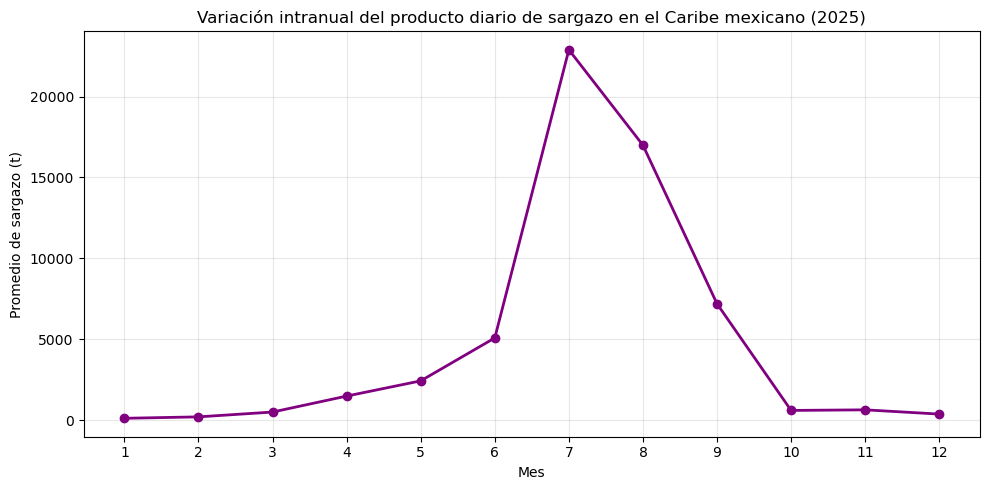

In [10]:
#Construcción de gráfica con librería "Matplotlib"

plt.figure(figsize=(10,5))

plt.plot(
    media_mensual.index, 
    media_mensual.values,
    marker="o", 
    color="purple", 
    linewidth=2
)

plt.xlabel("Mes")
plt.ylabel("Promedio de sargazo (t)")
plt.title("Variación intranual del producto diario de sargazo en el Caribe mexicano (2025)")

plt.xticks(range(1,13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:
#Construcción de función para la identificación de días con mayor abundancia de sargazo (que sobrepasen el percentil 90), 
# utilizando comandos básicos de Python y de la librería "Pandas".

def identificar_p90(datos, variable):
    percentil_90 = datos[variable].quantile(0.90)

#Filtrado de las filas para conservar únicamente aquellas en las que la variable supera el umbral establecido. 
    
    dias_max = datos[datos[variable]> percentil_90]

    return dias_max[["Date", variable]]



In [12]:
#Ejecución de la función creada

dias_p90 = identificar_p90(
    sargazo_2025, 
    "Day product · MODIS Aqua+Terra (t)"
)

print(dias_p90)

          Date  Day product · MODIS Aqua+Terra (t)
100 2025-04-11                               15170
138 2025-05-19                               15919
146 2025-05-27                               20937
151 2025-06-01                               60329
161 2025-06-11                               17068
166 2025-06-16                               18332
181 2025-07-01                              111587
183 2025-07-03                               26984
184 2025-07-04                               62963
186 2025-07-06                               52643
191 2025-07-11                              102776
193 2025-07-13                               25476
194 2025-07-14                               45376
196 2025-07-16                               85254
198 2025-07-18                               25911
199 2025-07-19                               27115
201 2025-07-21                               13133
203 2025-07-23                               54879
211 2025-07-31                 

In [13]:
# Cuantificación de días que sobrepasan el percentil 90

print ("Número de días superiores al P90:", len(dias_p90))

Número de días superiores al P90: 37
